# 🚗 YOLO Object Detection - Vehicle Dataset Pipeline
Pipeline gồm 5 giai đoạn:
1. **Cấu hình** - Thiết lập đường dẫn và tham số
2. **Chuyển đổi** - COCO → YOLO format (Bounding Box)
3. **Chia dataset** - Train/Val/Test = 70/20/10 (chia TRƯỚC, chỉ trên ảnh gốc)
4. **Augmentation** - Tăng cường CHỈ trên tập Train (BBox-safe, x3) → chống data leakage
5. **Đóng gói** - Tạo dataset.yaml

## 📦 Cell 1: Import & Cấu hình

In [1]:
import json, os, shutil, random, io
from pathlib import Path
from PIL import Image, ImageEnhance, ImageFilter
import numpy as np
from collections import defaultdict

# ===================== CẤU HÌNH =====================
# Đường dẫn TƯƠNG ĐỐI: notebook này nằm CÙNG thư mục với dataset COCO.
# (Nếu chạy báo lỗi không thấy file -> đặt COCO_DIR thành đường dẫn tuyệt đối tới folder 'train'.)
COCO_DIR = "Vehicles.v4-final_cuoi_cung.coco/train"
COCO_JSON = os.path.join(COCO_DIR, "_annotations.coco.json")
OUTPUT_DIR = "VEHICLE_DATASET_YOLO"          # dataset sạch sẽ tạo ra cạnh notebook
RANDOM_SEED = 42

# COCO cat_id -> YOLO class_id (bỏ cat 0 'Cars' rỗng)
CATEGORY_MAP = {1: 0, 2: 1, 3: 2, 4: 3}      # Bus, Motorcycle, car->Car, truck->Truck
CLASS_NAMES = ["Bus", "Motorcycle", "Car", "Truck"]

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("[OK] Config loaded")
print(f"  COCO source: {os.path.abspath(COCO_DIR)}")
print(f"  Output     : {os.path.abspath(OUTPUT_DIR)}")
print(f"  Ton tai nguon? {os.path.exists(COCO_JSON)}")
print(f"  Classes: {CLASS_NAMES}")

[OK] Config loaded
  COCO source: Vehicles.v4-final_cuoi_cung.coco\train
  Output     : VEHICLE_DATASET_YOLO
  Ton tai nguon? True
  Classes: ['Bus', 'Motorcycle', 'Car', 'Truck']


## 📂 Cell 2: Load COCO Annotations

In [2]:
# Load COCO JSON
with open(COCO_JSON, 'r', encoding='utf-8') as f:
    coco_data = json.load(f)

print(f'Images: {len(coco_data["images"])}')
print(f'Annotations: {len(coco_data["annotations"])}')

cat_counts = defaultdict(int)
for ann in coco_data['annotations']:
    cat_counts[ann['category_id']] += 1
print(f'\nAnnotation counts per category:')
cat_lookup = {c['id']: c['name'] for c in coco_data['categories']}
for cid, cnt in sorted(cat_counts.items()):
    print(f'  {cat_lookup.get(cid, cid)} (id={cid}): {cnt}')

Images: 1675
Annotations: 2459

Annotation counts per category:
  Bus (id=1): 536
  Motorcycle (id=2): 532
  car (id=3): 922
  truck (id=4): 469


## 🔄 Cell 3: Chuyển đổi BBox → YOLO Format
Format mỗi dòng label: `class_id cx cy w h`
Tất cả giá trị normalized [0, 1]

In [3]:
# Clean & create output dirs
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)

img_dir = os.path.join(OUTPUT_DIR, 'all_images')
lbl_dir = os.path.join(OUTPUT_DIR, 'all_labels')
os.makedirs(img_dir, exist_ok=True)
os.makedirs(lbl_dir, exist_ok=True)

# Build lookup
ann_by_img = defaultdict(list)
for ann in coco_data['annotations']:
    ann_by_img[ann['image_id']].append(ann)

converted = 0
total_objects = 0
class_counts = defaultdict(int)

for img_info in coco_data['images']:
    img_id = img_info['id']
    file_name = img_info['file_name']
    img_w, img_h = img_info['width'], img_info['height']
    
    src_path = os.path.join(COCO_DIR, file_name)
    if not os.path.exists(src_path):
        continue
    
    shutil.copy2(src_path, os.path.join(img_dir, file_name))
    
    label_name = os.path.splitext(file_name)[0] + '.txt'
    lines = []
    
    for ann in ann_by_img.get(img_id, []):
        cat_id = ann['category_id']
        if cat_id not in CATEGORY_MAP:
            continue
        
        yolo_cls = CATEGORY_MAP[cat_id]
        class_counts[CLASS_NAMES[yolo_cls]] += 1
        
        # BBox COCO→YOLO: COCO is [x_min, y_min, width, height]
        bx, by, bw, bh = ann['bbox']
        cx = max(0, min(1, (bx + bw/2) / img_w))
        cy = max(0, min(1, (by + bh/2) / img_h))
        nw = max(0, min(1, bw / img_w))
        nh = max(0, min(1, bh / img_h))
        
        line = f'{yolo_cls} {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}'
        lines.append(line)
        total_objects += 1
    
    with open(os.path.join(lbl_dir, label_name), 'w') as f:
        f.write('\n'.join(lines))
    converted += 1

print(f'[OK] Converted: {converted} images, {total_objects} objects')
print(f'Class distribution:')
for name, cnt in sorted(class_counts.items()):
    print(f'  {name}: {cnt}')

[OK] Converted: 1675 images, 2459 objects
Class distribution:
  Bus: 536
  Car: 922
  Motorcycle: 532
  Truck: 469


## ✂️ Cell 4: Loại ảnh trùng + Chia Dataset theo ẢNH GỐC (70/20/10)
**Chống data leakage TRIỆT ĐỂ — 2 bước:**
1. **Loại ảnh trùng y hệt** (aHash) — giữ 1 bản.
2. **Chia theo ẢNH GỐC (UUID)**: Roboflow đã nhân 1 ảnh thành nhiều bản (đuôi `.rf.` khác nhau). Ta gom **tất cả bản của cùng 1 ảnh về CÙNG 1 tập** → không có bản nào của ảnh test lọt sang train.

> ⚠️ Nếu chia ngẫu nhiên theo *file* (cách cũ) sẽ có ~75 ảnh gốc bị rò rỉ giữa train/test. Chia theo *ảnh gốc* → **0 rò rỉ**.

In [4]:
# ============================================================
#  CHỐNG LEAKAGE: (1) loại ảnh trùng y hệt  (2) chia theo ẢNH GỐC (UUID)
# ============================================================
def img_uuid(fname):
    """ID ảnh gốc = phần trước '.rf.' (bỏ hậu tố augment của Roboflow)."""
    n = os.path.splitext(fname)[0]
    return n.split('.rf.')[0] if '.rf.' in n else n

def avg_hash(path, size=8):
    """aHash 64-bit để phát hiện ảnh trùng y hệt."""
    im = Image.open(path).convert('L').resize((size, size))
    px = list(im.getdata()); avg = sum(px) / len(px)
    bits = 0
    for i, p in enumerate(px):
        if p >= avg:
            bits |= (1 << i)
    return bits

# 1) Chỉ giữ ảnh có nhãn hợp lệ (loại ảnh không có xe)
all_imgs = sorted([f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))])
valid_imgs = [f for f in all_imgs
              if os.path.getsize(os.path.join(lbl_dir, os.path.splitext(f)[0] + '.txt')) > 0]

# 2) Loại ảnh TRÙNG Y HỆT (giữ 1 bản)
seen_hash, dedup_imgs, removed = set(), [], 0
for f in valid_imgs:
    h = avg_hash(os.path.join(img_dir, f))
    if h in seen_hash:
        removed += 1
        continue
    seen_hash.add(h); dedup_imgs.append(f)
print(f'[OK] Loại {removed} ảnh trùng y hệt -> còn {len(dedup_imgs)} ảnh')

# 3) Gom theo ẢNH GỐC (UUID) rồi chia 70/20/10 -> mọi bản của 1 ảnh ở CÙNG 1 tập
groups = defaultdict(list)
for f in dedup_imgs:
    groups[img_uuid(f)].append(f)
uuids = list(groups.keys())
random.shuffle(uuids)
n = len(uuids)
n_train = round(n * 0.7)
n_val   = round(n * 0.2)
train_u = set(uuids[:n_train])
val_u   = set(uuids[n_train:n_train + n_val])

train_orig, val_imgs, test_imgs = [], [], []
for u, fs in groups.items():
    bucket = train_orig if u in train_u else (val_imgs if u in val_u else test_imgs)
    bucket.extend(fs)

# 4) Tạo thư mục & copy
for split_name in ['train', 'val', 'test']:
    os.makedirs(os.path.join(OUTPUT_DIR, split_name, 'images'), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_DIR, split_name, 'labels'), exist_ok=True)

def copy_split(files, split_name):
    s_img = os.path.join(OUTPUT_DIR, split_name, 'images')
    s_lbl = os.path.join(OUTPUT_DIR, split_name, 'labels')
    for fname in files:
        lbl_name = os.path.splitext(fname)[0] + '.txt'
        shutil.copy2(os.path.join(img_dir, fname), os.path.join(s_img, fname))
        shutil.copy2(os.path.join(lbl_dir, lbl_name), os.path.join(s_lbl, lbl_name))

copy_split(train_orig, 'train')
copy_split(val_imgs,   'val')
copy_split(test_imgs,  'test')

print(f'[OK] Chia theo ẢNH GỐC: {n_train}/{n_val}/{n - n_train - n_val} ảnh gốc '
      f'-> train={len(train_orig)} val={len(val_imgs)} test={len(test_imgs)} file')
print('     → Val/Test chỉ chứa ảnh gốc, KHÔNG được augment, KHÔNG leakage.')

3995277472.py:12: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  px = list(im.getdata()); avg = sum(px) / len(px)


[OK] Loại 65 ảnh trùng y hệt -> còn 1610 ảnh
[OK] Chia theo ẢNH GỐC: 1045/299/149 ảnh gốc -> train=1119 val=324 test=167 file
     → Val/Test chỉ chứa ảnh gốc, KHÔNG được augment, KHÔNG leakage.


## 🔍 Cell 4b: Minh họa "ảnh trùng" trông như thế nào
Cell này hiển thị vài cặp ảnh **trùng y hệt** trong bộ gốc để người xem dễ hiểu: chúng **cùng nội dung** (cùng xe, cùng góc), chỉ khác **độ sáng rất nhẹ** — nên ta giữ 1 bản (xanh), loại bản còn lại (đỏ). Đây là minh chứng trực quan cho bước làm sạch dữ liệu.

3086689820.py:9: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  px = list(im.getdata()); avg = sum(px) / len(px)


Số NHÓM ảnh trùng y hệt: 57  (mỗi nhóm giữ 1, loại phần còn lại)


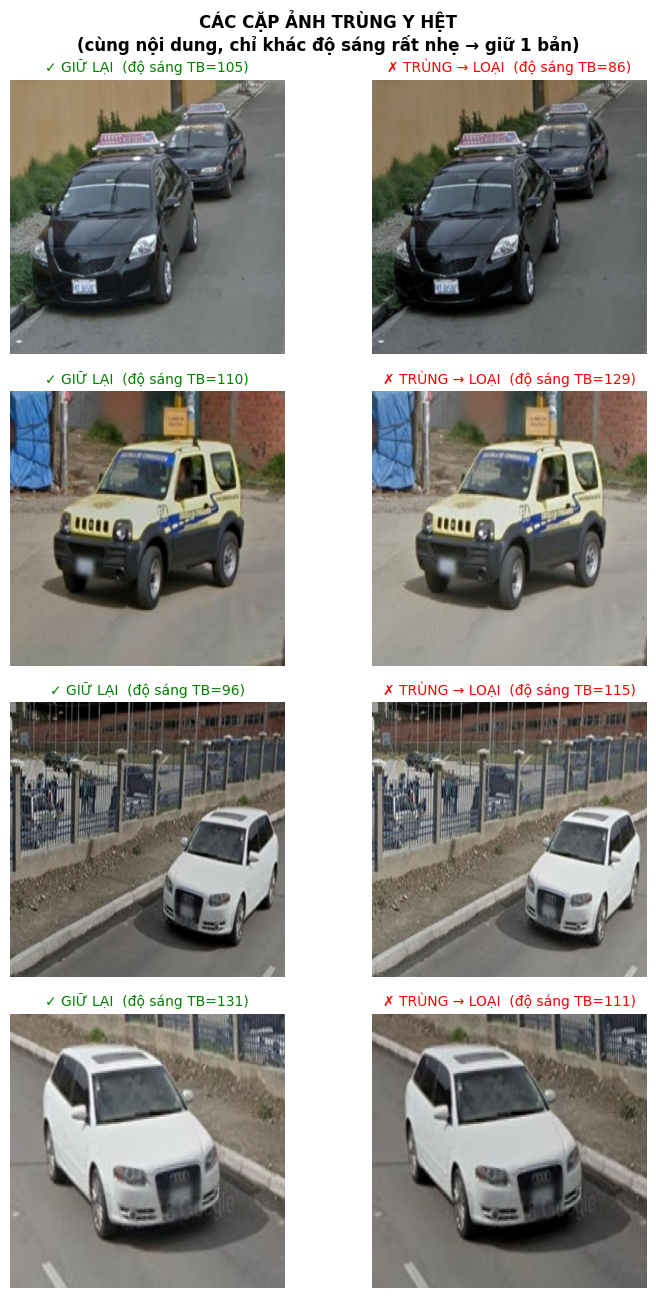

In [5]:
# ============================================================
#  MINH HỌA: "Ảnh trùng" trông như thế nào (để người xem dễ hiểu)
# ============================================================
import glob
import matplotlib.pyplot as plt

def _ahash(path, size=8):
    im = Image.open(path).convert('L').resize((size, size))
    px = list(im.getdata()); avg = sum(px) / len(px)
    b = 0
    for i, p in enumerate(px):
        if p >= avg: b |= (1 << i)
    return b

# Gom ảnh TRÙNG Y HỆT (cùng aHash) trong bộ gốc
_imgs = [p for p in glob.glob(os.path.join(COCO_DIR, '*'))
         if p.lower().endswith(('.jpg', '.jpeg', '.png'))]
_buckets = defaultdict(list)
for p in _imgs:
    _buckets[_ahash(p)].append(p)
_dup_groups = [v for v in _buckets.values() if len(v) > 1]
print(f"Số NHÓM ảnh trùng y hệt: {len(_dup_groups)}  (mỗi nhóm giữ 1, loại phần còn lại)")

# Hiển thị tối đa 4 nhóm, mỗi nhóm 2 ảnh cạnh nhau
_show = _dup_groups[:4]
fig, axes = plt.subplots(len(_show), 2, figsize=(8, 3.3 * len(_show)))
if len(_show) == 1:
    axes = [axes]
for row, grp in zip(axes, _show):
    for j, ax in enumerate(row):
        if j < len(grp):
            im = Image.open(grp[j]).convert('RGB')
            bright = np.array(im.convert('L')).mean()
            ax.imshow(im)
            tag = "✓ GIỮ LẠI" if j == 0 else "✗ TRÙNG → LOẠI"
            ax.set_title(f"{tag}  (độ sáng TB={bright:.0f})",
                         fontsize=10, color=('green' if j == 0 else 'red'))
        ax.axis('off')
fig.suptitle("CÁC CẶP ẢNH TRÙNG Y HỆT\n(cùng nội dung, chỉ khác độ sáng rất nhẹ → giữ 1 bản)",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 🎨 Cell 5: Định nghĩa hàm Augmentation (BBox-Safe)
Chỉ dùng các phép biến đổi không thay đổi tọa độ BBox:
- Brightness, Contrast, Saturation
- Gaussian noise, Blur, Sharpen, v.v.

*(Cell này chỉ ĐỊNH NGHĨA hàm — augment thật được chạy ở Cell 6, SAU khi đã chia tập.)*

In [6]:
def augment_image(img_path, label_path, out_img_path, out_lbl_path, aug_type):
    try:
        img = Image.open(img_path).convert('RGB')
    except Exception:
        return False
    
    img_np = np.array(img)
    
    if aug_type == 'brightness_up':
        img = ImageEnhance.Brightness(img).enhance(random.uniform(1.15, 1.45))
    elif aug_type == 'brightness_down':
        img = ImageEnhance.Brightness(img).enhance(random.uniform(0.55, 0.85))
    elif aug_type == 'contrast_up':
        img = ImageEnhance.Contrast(img).enhance(random.uniform(1.2, 1.6))
    elif aug_type == 'contrast_down':
        img = ImageEnhance.Contrast(img).enhance(random.uniform(0.5, 0.8))
    elif aug_type == 'saturation_up':
        img = ImageEnhance.Color(img).enhance(random.uniform(1.3, 1.8))
    elif aug_type == 'saturation_down':
        img = ImageEnhance.Color(img).enhance(random.uniform(0.3, 0.7))
    elif aug_type == 'gaussian_noise':
        noise = np.random.normal(0, random.uniform(8, 25), img_np.shape).astype(np.int16)
        img_np = np.clip(img_np.astype(np.int16) + noise, 0, 255).astype(np.uint8)
        img = Image.fromarray(img_np)
    elif aug_type == 'blur':
        img = img.filter(ImageFilter.GaussianBlur(radius=random.uniform(0.5, 1.5)))
    elif aug_type == 'sharpen':
        img = ImageEnhance.Sharpness(img).enhance(random.uniform(1.5, 3.0))
    elif aug_type == 'jpeg_compress':
        buf = io.BytesIO()
        img.save(buf, format='JPEG', quality=random.randint(30, 60))
        buf.seek(0)
        img = Image.open(buf).convert('RGB')
    elif aug_type == 'channel_shuffle':
        ch = list(img.split()); order = [0,1,2]; random.shuffle(order)
        img = Image.merge('RGB', [ch[i] for i in order])
    elif aug_type == 'grayscale_mix':
        gray = np.array(img.convert('L').convert('RGB'), dtype=np.float32)
        alpha = random.uniform(0.3, 0.7)
        mixed = (alpha * img_np.astype(np.float32) + (1-alpha) * gray).astype(np.uint8)
        img = Image.fromarray(mixed)
    
    img.save(out_img_path, quality=95)
    shutil.copy2(label_path, out_lbl_path)
    return True

print('[OK] Augmentation function defined')

[OK] Augmentation function defined


## 🎨 Cell 6: Augmentation CHỈ trên tập Train (x3)
Mỗi ảnh GỐC trong tập **train** sinh thêm **2 ảnh augment** (2 phép biến đổi khác nhau, BBox-safe).
Tập val/test giữ nguyên 100% ảnh gốc → mô hình được đánh giá hoàn toàn trung thực.

In [7]:
# AUGMENT CHỈ trên tập TRAIN (x3): mỗi ảnh train gốc sinh thêm 2 ảnh augment
train_img_dir = os.path.join(OUTPUT_DIR, 'train', 'images')
train_lbl_dir = os.path.join(OUTPUT_DIR, 'train', 'labels')

aug_types = ['brightness_up','brightness_down','contrast_up','contrast_down',
             'saturation_up','saturation_down','gaussian_noise','blur',
             'sharpen','jpeg_compress','channel_shuffle','grayscale_mix']

aug_count = 0
for img_name in train_orig:
    chosen_augs = random.sample(aug_types, 2)   # 2 phép KHÁC NHAU cho mỗi ảnh
    base, ext = os.path.splitext(img_name)
    for aug_type in chosen_augs:
        aug_img = f'{base}_aug_{aug_type}{ext}'
        aug_lbl = f'{base}_aug_{aug_type}.txt'
        dst_img = os.path.join(train_img_dir, aug_img)
        if not os.path.exists(dst_img):
            ok = augment_image(
                os.path.join(train_img_dir, img_name),
                os.path.join(train_lbl_dir, base + '.txt'),
                dst_img,
                os.path.join(train_lbl_dir, aug_lbl),
                aug_type)
            if ok:
                aug_count += 1
                if aug_count % 500 == 0:
                    print(f'  Progress: {aug_count}/{len(train_orig) * 2}')

# Dọn thư mục tạm chứa toàn bộ ảnh gốc
shutil.rmtree(img_dir)
shutil.rmtree(lbl_dir)

n_train_total = len(train_orig) + aug_count
print(f'\n[OK] Augmented (CHỈ train): {aug_count}')
print(f'  train: {n_train_total} (gốc {len(train_orig)} + augment {aug_count})')
print(f'  val  : {len(val_imgs)} | test: {len(test_imgs)}  (đều 100% ảnh gốc)')
print('[OK] Đã dọn thư mục tạm. Pipeline KHÔNG còn data leakage.')

  Progress: 500/2238
  Progress: 1000/2238
  Progress: 1500/2238
  Progress: 2000/2238

[OK] Augmented (CHỈ train): 2238
  train: 3357 (gốc 1119 + augment 2238)
  val  : 324 | test: 167  (đều 100% ảnh gốc)
[OK] Đã dọn thư mục tạm. Pipeline KHÔNG còn data leakage.


## 📝 Cell 7: Tạo dataset.yaml

In [8]:
yaml_content = f"""# YOLO Vehicle Detection Dataset
path: {OUTPUT_DIR.replace(os.sep, '/')}
train: train/images
val: val/images
test: test/images

names:
  0: Bus
  1: Motorcycle
  2: Car
  3: Truck

nc: {len(CLASS_NAMES)}
"""

yaml_path = os.path.join(OUTPUT_DIR, 'dataset.yaml')
with open(yaml_path, 'w', encoding='utf-8') as f:
    f.write(yaml_content)

print(f'[OK] Created: {yaml_path}\n')
print(yaml_content)

[OK] Created: VEHICLE_DATASET_YOLO\dataset.yaml

# YOLO Vehicle Detection Dataset
path: VEHICLE_DATASET_YOLO
train: train/images
val: val/images
test: test/images

names:
  0: Bus
  1: Motorcycle
  2: Car
  3: Truck

nc: 4

